In [ ]:
import numpy as np
from sentence_transformers import SentenceTransformer

sentences = [
    "Você já comeu macarrão?",
    "Amo comer macarrão",
    "A bolsa de valores caiu",
    "SIm, eu vi que a bolsa de valores caiu, fiquei preocupado"
]


model = SentenceTransformer('all-MiniLM-L6-v2')
S = model.encode(sentences)

print("\nEmbeddings (S):")
print(S.shape)  
print(S)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 10377.20it/s]
BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



Embeddings (S):
(4, 384)
[[-0.05991548  0.02580586 -0.03681251 ...  0.0454679  -0.02289378
  -0.01613131]
 [-0.04854359  0.05643677 -0.05710015 ...  0.02885966 -0.00812406
  -0.01318522]
 [-0.11045008  0.0684839  -0.07584474 ... -0.02915965 -0.01245591
  -0.01473674]
 [-0.06767141  0.06523593 -0.08063839 ...  0.01075965 -0.0028436
  -0.03466617]]


In [26]:
scores = S @ S.T

n = len(sentences)
A = np.zeros((n, n))

for i in range(n):
    for j in range(n):
        if j < i: 
            A[i, j] = scores[i, j]

print(A)

[[0.         0.         0.         0.        ]
 [0.79234099 0.         0.         0.        ]
 [0.43009818 0.41630951 0.         0.        ]
 [0.49774605 0.45363873 0.74113238 0.        ]]


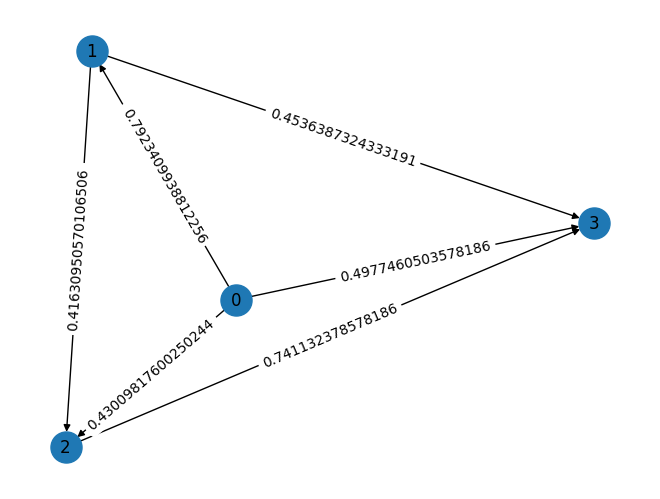

In [29]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()

for i, s in enumerate(sentences):
    G.add_node(i, label=s)

for i in range(4):
    for j in range(4):
        weight = A[i, j]
        if weight > 0.2:  
            G.add_edge(j, i, weight=weight) 

pos = nx.spring_layout(G)

nx.draw(G, pos, with_labels=True, node_size=500)
labels = nx.get_edge_attributes(G, 'weight')
nx.draw_networkx_edge_labels(G, pos, edge_labels=labels)

plt.show()